In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

%matplotlib inline

# --- Spójna paleta kolorów dla wszystkich wykresów w notebooku ---
CAT = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
INK = '#0b0b0b'
INK2 = '#52514e'
MUTED = '#898781'
GRID = '#e1e0d9'
SURFACE = '#fcfcfb'
DIVERGING = LinearSegmentedColormap.from_list('diverging', ['#e34948', '#f0efec', '#2a78d6'])

plt.rcParams.update({
    'figure.facecolor': SURFACE,
    'axes.facecolor': SURFACE,
    'axes.edgecolor': GRID,
    'axes.labelcolor': INK2,
    'text.color': INK,
    'xtick.color': MUTED,
    'ytick.color': MUTED,
    'grid.color': GRID,
    'axes.grid': True,
    'grid.linewidth': 0.8,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11,
    'figure.dpi': 100,
})

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)

RANDOM_STATE = 42

## 1. Wczytanie danych

In [5]:
df_raw = pd.read_csv('data\walmart_cleaned.csv', index_col=0)
print(f"Liczba wierszy: {df_raw.shape[0]:,}".replace(',', ' '))
print(f"Liczba kolumn: {df_raw.shape[1]}")
df_raw.head()

Liczba wierszy: 421 570
Liczba kolumn: 16


,Store,Date,IsHoliday,Dept,Weekly_Sales,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
0,1,2010-02-05,0,1.0,24924.50,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,3,151315
1,1,2010-02-05,0,26.0,11737.12,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,3,151315
2,1,2010-02-05,0,17.0,13223.76,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,3,151315
3,1,2010-02-05,0,45.0,37.44,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,3,151315
4,1,2010-02-05,0,28.0,1085.29,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,3,151315


In [6]:
df_raw.dtypes.to_frame('dtype')

,dtype
Store,int64
Date,object
IsHoliday,int64
Dept,float64
Weekly_Sales,float64
Temperature,float64
Fuel_Price,float64
MarkDown1,float64
MarkDown2,float64
MarkDown3,float64


## 2. Jakość danych

In [7]:
quality = pd.DataFrame({
    'braki (NaN)': df_raw.isna().sum(),
    '% braków': (df_raw.isna().mean()*100).round(2),
    'unikalne wartości': df_raw.nunique(),
})
print("Duplikaty wierszy:", df_raw.duplicated().sum())
quality

Duplikaty wierszy: 0


,braki (NaN),% braków,unikalne wartości
Store,0,0.0,45
Date,0,0.0,143
IsHoliday,0,0.0,2
Dept,0,0.0,81
Weekly_Sales,0,0.0,359464
Temperature,0,0.0,3528
Fuel_Price,0,0.0,892
MarkDown1,0,0.0,2278
MarkDown2,0,0.0,1499
MarkDown3,0,0.0,1662


In [5]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Store,421570.0,22.200546,12.785297,1.000,11.000000,22.00000,33.000000,45.000000
IsHoliday,421570.0,0.070358,0.255750,0.000,0.000000,0.00000,0.000000,1.000000
Dept,421570.0,44.260317,30.492054,1.000,18.000000,37.00000,74.000000,99.000000
Weekly_Sales,421570.0,15981.258123,22711.183519,-4988.940,2079.650000,7612.03000,20205.852500,693099.360000
Temperature,421570.0,60.090059,18.447931,-2.060,46.680000,62.09000,74.280000,100.140000
Fuel_Price,421570.0,3.361027,0.458515,2.472,2.933000,3.45200,3.738000,4.468000
MarkDown1,421570.0,2590.074819,6052.385934,0.000,0.000000,0.00000,2809.050000,88646.760000
MarkDown2,421570.0,879.974298,5084.538801,-265.760,0.000000,0.00000,2.200000,104519.540000
MarkDown3,421570.0,468.087665,5528.873453,-29.100,0.000000,0.00000,4.540000,141630.610000
MarkDown4,421570.0,1083.132268,3894.529945,0.000,0.000000,0.00000,425.290000,67474.850000


In [6]:
print("Liczba sklepów (Store):", df_raw['Store'].nunique())
print("Liczba działów (Dept):", df_raw['Dept'].nunique())
print("Unikalne kombinacje Store-Dept:", df_raw.groupby(['Store','Dept']).ngroups)
print("Zakres dat:", df_raw['Date'].min(), '-', df_raw['Date'].max())
print("Liczba unikalnych tygodni:", df_raw['Date'].nunique())
print("\nRozkład Type:\n", df_raw['Type'].value_counts())
print("\nRozkład IsHoliday:\n", df_raw['IsHoliday'].value_counts())
print("\nWiersze z Weekly_Sales < 0:", (df_raw['Weekly_Sales'] < 0).sum())
print("Wiersze z Weekly_Sales == 0:", (df_raw['Weekly_Sales'] == 0).sum())
for c in ['MarkDown1','MarkDown2','MarkDown3','MarkDown4','MarkDown5']:
    print(f"Ujemne wartości w {c}:", (df_raw[c] < 0).sum())

Liczba sklepów (Store): 45
Liczba działów (Dept): 81
Unikalne kombinacje Store-Dept: 3331


Zakres dat: 2010-02-05 - 2012-10-26
Liczba unikalnych tygodni: 143

Rozkład Type:
 Type
3    215478
2    163495
1     42597
Name: count, dtype: int64

Rozkład IsHoliday:
 IsHoliday
0    391909
1     29661
Name: count, dtype: int64

Wiersze z Weekly_Sales < 0: 1285
Wiersze z Weekly_Sales == 0: 73
Ujemne wartości w MarkDown1: 0
Ujemne wartości w MarkDown2: 1311
Ujemne wartości w MarkDown3: 257
Ujemne wartości w MarkDown4: 0
Ujemne wartości w MarkDown5: 0


**Obserwacje o jakości danych.** Zbiór nie zawiera braków danych ani duplikatów wierszy —
to już wynik wcześniejszego, częściowego przetworzenia (m.in. `Type` jest zakodowany
liczbowo jako 1/2/3, a nie jako oryginalne litery A/B/C, więc w dalszej części traktujemy
go jako zmienną nominalną bez zakładania kolejności). Wymaga jednak dalszego czyszczenia:
kolumna `Date` jest tekstem, 1 285 wierszy (0,30%) ma ujemną `Weekly_Sales`, a `MarkDown2`
i `MarkDown3` zawierają odpowiednio 1 311 i 257 ujemnych wartości. Dane obejmują 143
kolejne tygodnie (2010-02-05 – 2012-10-26), 45 sklepów, 81 działów i 3 331 unikalnych par
sklep–dział, przy czym nie każda para występuje we wszystkich tygodniach.

## 3. Analiza eksploracyjna (EDA)

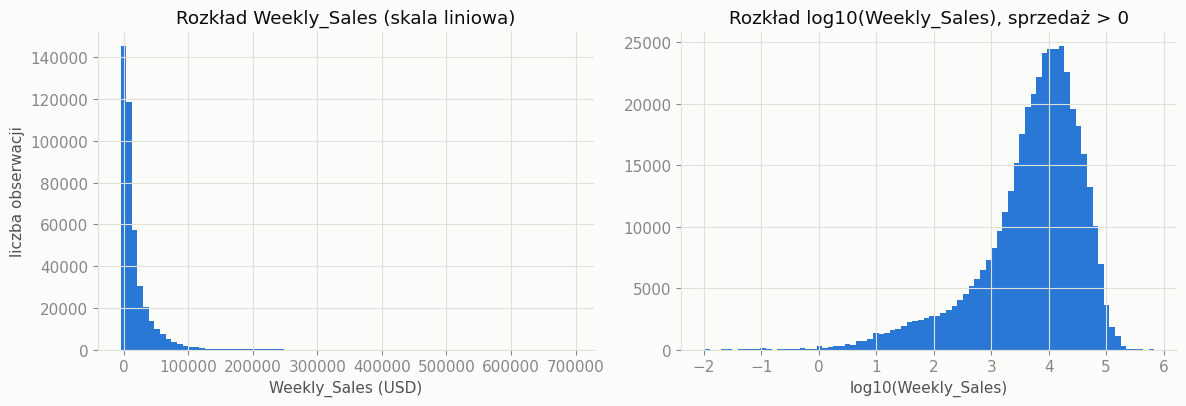

count    421570.000000
mean      15981.258123
std       22711.183519
min       -4988.940000
25%        2079.650000
50%        7612.030000
75%       20205.852500
max      693099.360000
Name: Weekly_Sales, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(df_raw['Weekly_Sales'], bins=80, color=CAT[0], edgecolor='none')
axes[0].set_title('Rozkład Weekly_Sales (skala liniowa)')
axes[0].set_xlabel('Weekly_Sales (USD)')
axes[0].set_ylabel('liczba obserwacji')

pos = df_raw.loc[df_raw['Weekly_Sales'] > 0, 'Weekly_Sales']
axes[1].hist(np.log10(pos), bins=80, color=CAT[0], edgecolor='none')
axes[1].set_title('Rozkład log10(Weekly_Sales), sprzedaż > 0')
axes[1].set_xlabel('log10(Weekly_Sales)')
plt.tight_layout()
plt.show()

print(df_raw['Weekly_Sales'].describe())

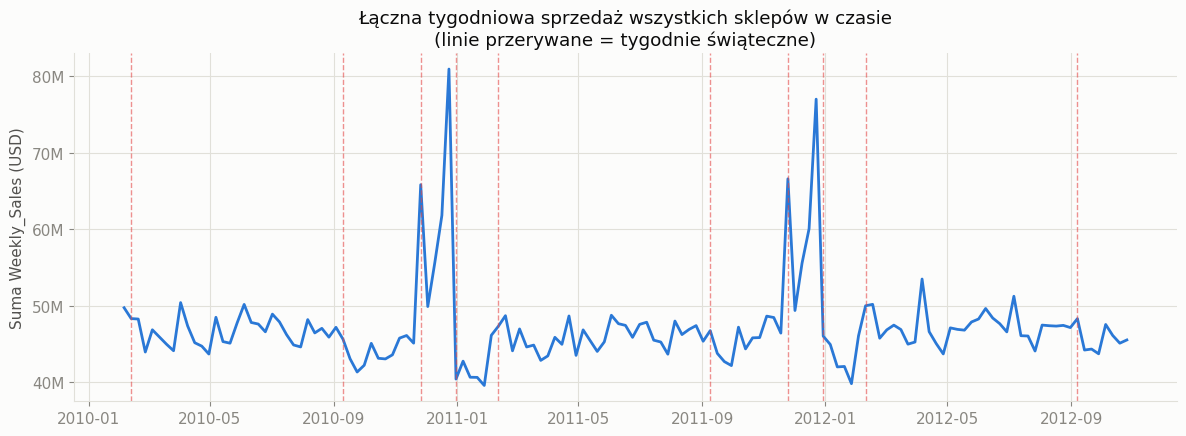

In [8]:
tmp = df_raw.copy()
tmp['Date'] = pd.to_datetime(tmp['Date'])
weekly_total = tmp.groupby('Date')['Weekly_Sales'].sum()
holiday_dates = tmp.loc[tmp['IsHoliday'] == 1, 'Date'].unique()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(weekly_total.index, weekly_total.values, color=CAT[0], linewidth=2)
for hd in holiday_dates:
    ax.axvline(hd, color=CAT[7], linewidth=1, linestyle='--', alpha=0.6)
ax.set_title('Łączna tygodniowa sprzedaż wszystkich sklepów w czasie\n(linie przerywane = tygodnie świąteczne)')
ax.set_ylabel('Suma Weekly_Sales (USD)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'{x/1e6:.0f}M'))
plt.tight_layout()
plt.show()

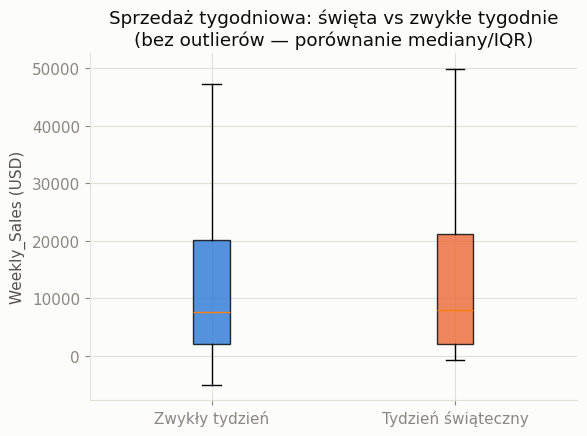

,mean,median,std,count
IsHoliday,,,,
0,15901.445069,7589.95,22330.747450,391909
1,17035.823187,7947.74,27222.000409,29661


In [9]:
fig, ax = plt.subplots(figsize=(6, 4.5))
data_h = [df_raw.loc[df_raw['IsHoliday'] == 0, 'Weekly_Sales'],
          df_raw.loc[df_raw['IsHoliday'] == 1, 'Weekly_Sales']]
bp = ax.boxplot(data_h, tick_labels=['Zwykły tydzień', 'Tydzień świąteczny'],
                 showfliers=False, patch_artist=True)
for patch, color in zip(bp['boxes'], [CAT[0], CAT[1]]):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)
ax.set_ylabel('Weekly_Sales (USD)')
ax.set_title('Sprzedaż tygodniowa: święta vs zwykłe tygodnie\n(bez outlierów — porównanie mediany/IQR)')
plt.tight_layout()
plt.show()

df_raw.groupby('IsHoliday')['Weekly_Sales'].agg(['mean', 'median', 'std', 'count'])

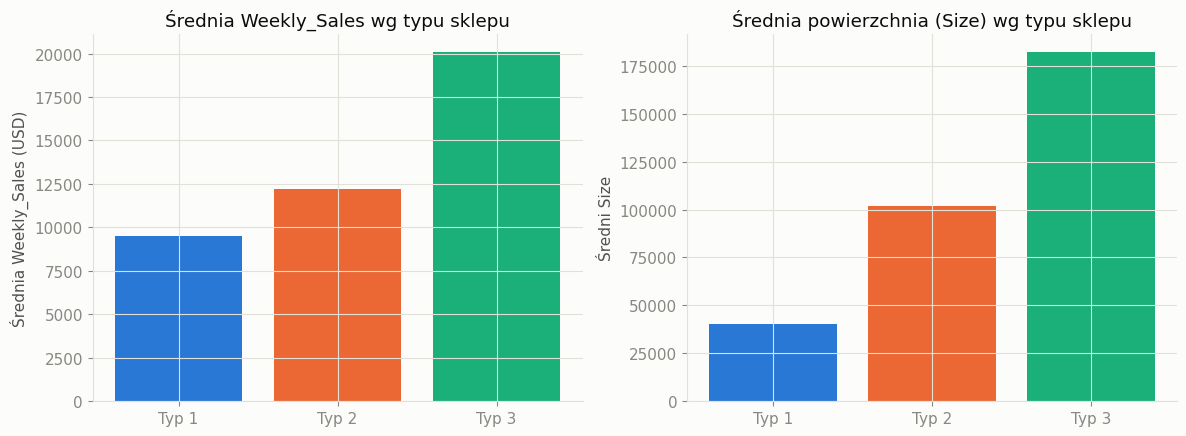

,Weekly_Sales,Size
TypeLabel,,
Typ 1,9519.532538,40535.725286
Typ 2,12237.075977,101818.735827
Typ 3,20099.568043,182231.285486


In [10]:
type_labels = {1: 'Typ 1', 2: 'Typ 2', 3: 'Typ 3'}
tmp2 = df_raw.copy()
tmp2['TypeLabel'] = tmp2['Type'].map(type_labels)
order = ['Typ 1', 'Typ 2', 'Typ 3']

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
means = tmp2.groupby('TypeLabel')['Weekly_Sales'].mean().reindex(order)
axes[0].bar(order, means.values, color=CAT[:3])
axes[0].set_title('Średnia Weekly_Sales wg typu sklepu')
axes[0].set_ylabel('Średnia Weekly_Sales (USD)')

sizes = tmp2.groupby('TypeLabel')['Size'].mean().reindex(order)
axes[1].bar(order, sizes.values, color=CAT[:3])
axes[1].set_title('Średnia powierzchnia (Size) wg typu sklepu')
axes[1].set_ylabel('Średni Size')
plt.tight_layout()
plt.show()

tmp2.groupby('TypeLabel')[['Weekly_Sales', 'Size']].mean()

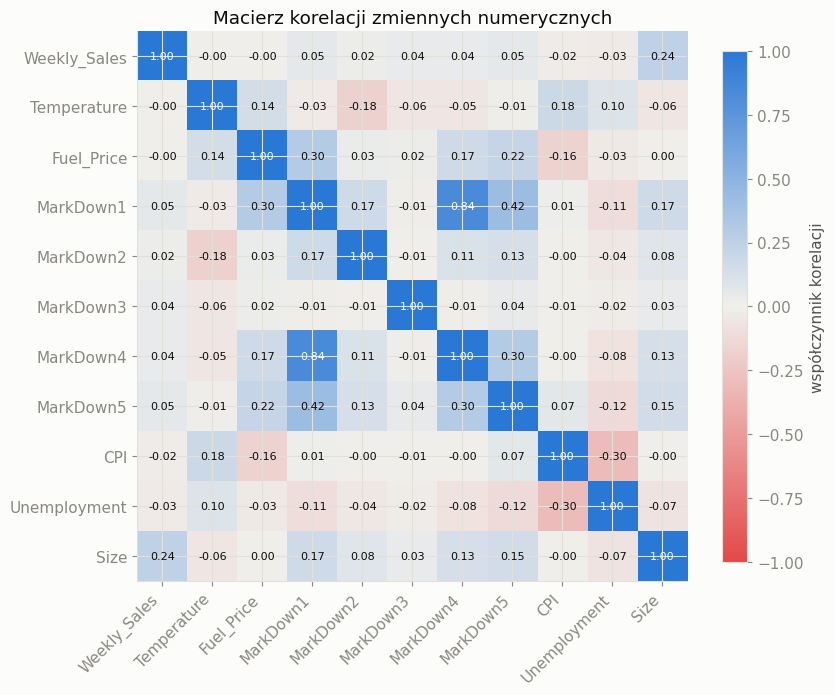

In [11]:
num_cols = ['Weekly_Sales', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2',
            'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'Size']
corr = df_raw[num_cols].corr()

fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols))); ax.set_xticklabels(num_cols, rotation=45, ha='right')
ax.set_yticks(range(len(num_cols))); ax.set_yticklabels(num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        v = corr.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(v) > 0.6 else INK)
ax.set_title('Macierz korelacji zmiennych numerycznych')
fig.colorbar(im, ax=ax, shrink=0.8, label='współczynnik korelacji')
plt.tight_layout()
plt.show()

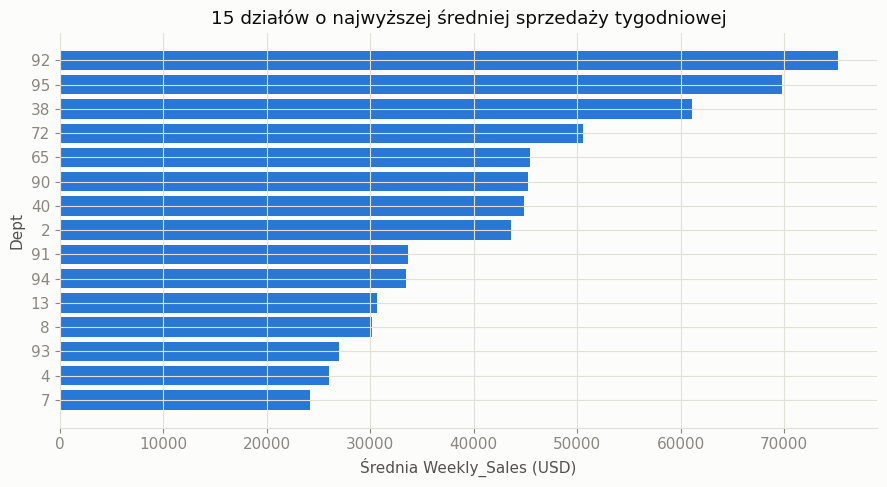

In [12]:
dept_avg = df_raw.groupby('Dept')['Weekly_Sales'].mean().sort_values(ascending=False)
top15 = dept_avg.head(15)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top15.index.astype(int).astype(str)[::-1], top15.values[::-1], color=CAT[0])
ax.set_xlabel('Średnia Weekly_Sales (USD)')
ax.set_ylabel('Dept')
ax.set_title('15 działów o najwyższej średniej sprzedaży tygodniowej')
plt.tight_layout()
plt.show()

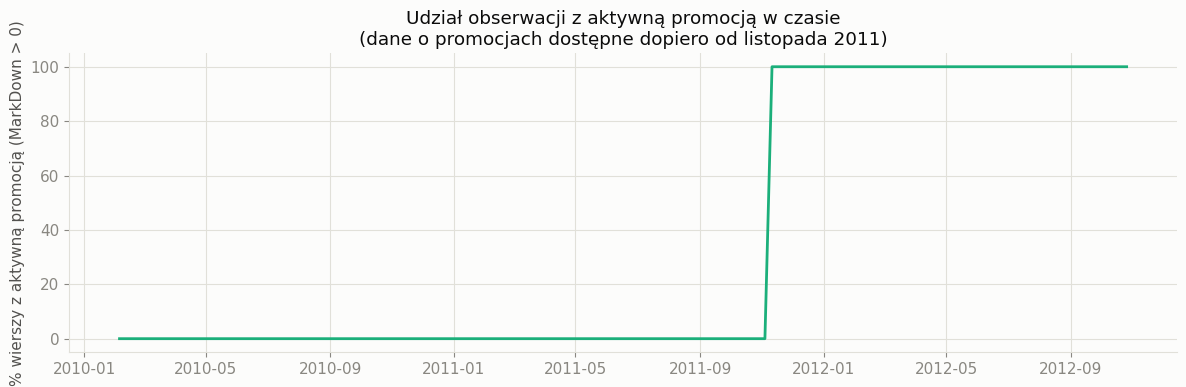

In [13]:
tmp3 = df_raw.copy()
tmp3['Date'] = pd.to_datetime(tmp3['Date'])
md_cols = ['MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5']
active = tmp3.groupby('Date').apply(lambda d: (d[md_cols].sum(axis=1) > 0).mean())

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(active.index, active.values * 100, color=CAT[2], linewidth=2)
ax.set_ylabel('% wierszy z aktywną promocją (MarkDown > 0)')
ax.set_title('Udział obserwacji z aktywną promocją w czasie\n(dane o promocjach dostępne dopiero od listopada 2011)')
plt.tight_layout()
plt.show()

**Kluczowe wnioski z EDA.** Rozkład `Weekly_Sales` jest silnie prawoskośny — większość
obserwacji to sprzedaż niska/średnia, ale ogon rozkładu sięga setek tysięcy dolarów
tygodniowo dla wybranych działów w tygodniach świątecznych (np. Dział 72, prawdopodobnie
elektronika, w tygodniu Święta Dziękczynienia). Sprzedaż w tygodniach świątecznych jest
wyraźnie wyższa niż w zwykłych tygodniach, choć różnica median jest umiarkowana, a
najsilniejszy efekt widać w prawym ogonie rozkładu (nieliczne, bardzo wysokie wartości).
Sklepy Typu 1 mają największą średnią powierzchnię i średnią sprzedaż, co sugeruje, że
`Type` w dużej mierze koduje wielkość formatu sklepu; korelacja między `Size` a
`Weekly_Sales` jest dodatnia, ale umiarkowana (0,24) — powierzchnia sklepu ma znaczenie, lecz nie
tłumaczy sama w sobie większości zmienności sprzedaży. Zmienne makroekonomiczne (`CPI`, `Unemployment`,
`Fuel_Price`, `Temperature`) mają słabą korelację liniową ze sprzedażą na poziomie
pojedynczej obserwacji, natomiast promocje (`MarkDown`) pojawiają się dopiero od listopada
2011 r. — co należy uwzględnić w modelowaniu, bo dla wcześniejszego okresu ich wartość
zerowa nie oznacza braku promocji, tylko brak danych o promocjach w tamtym okresie.

## 4. Czyszczenie danych

In [14]:
df = df_raw.copy()

# 1) Parsowanie daty
df['Date'] = pd.to_datetime(df['Date'])

# 2) Ujemne MarkDown2/MarkDown3 - drobne korekty/błędy danych źródłowych - przycinamy do 0
for col in ['MarkDown2', 'MarkDown3']:
    n_neg = (df[col] < 0).sum()
    df[col] = df[col].clip(lower=0)
    print(f"{col}: przycięto {n_neg} ujemnych wartości do 0")

# 3) Ujemna Weekly_Sales to realny fakt biznesowy (zwroty netto przewyższające sprzedaż
#    w danym tygodniu), a nie błąd - zostawiamy wartości, ale oznaczamy flagą.
df['is_negative_sales'] = (df['Weekly_Sales'] < 0).astype(int)
print(f"\nOznaczono {df['is_negative_sales'].sum()} wierszy "
      f"({df['is_negative_sales'].mean()*100:.2f}%) z ujemną sprzedażą jako zwroty netto.")

# 4) Utrwalenie typów kategorycznych/całkowitych
df['Store'] = df['Store'].astype(int)
df['Dept'] = df['Dept'].astype(int)
df['Type'] = df['Type'].astype(int)
df['IsHoliday'] = df['IsHoliday'].astype(int)

print("\nDuplikaty po czyszczeniu:", df.duplicated().sum())

df = df.sort_values(['Store', 'Dept', 'Date']).reset_index(drop=True)
df.head()

MarkDown2: przycięto 1311 ujemnych wartości do 0
MarkDown3: przycięto 257 ujemnych wartości do 0

Oznaczono 1285 wierszy (0.30%) z ujemną sprzedażą jako zwroty netto.

Duplikaty po czyszczeniu: 0


,Store,Date,IsHoliday,Dept,Weekly_Sales,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size,is_negative_sales
0,1,2010-02-05,0,1,24924.50,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,3,151315,0
1,1,2010-02-12,1,1,46039.49,38.51,2.548,0.0,0.0,0.0,0.0,0.0,211.242170,8.106,3,151315,0
2,1,2010-02-19,0,1,41595.55,39.93,2.514,0.0,0.0,0.0,0.0,0.0,211.289143,8.106,3,151315,0
3,1,2010-02-26,0,1,19403.54,46.63,2.561,0.0,0.0,0.0,0.0,0.0,211.319643,8.106,3,151315,0
4,1,2010-03-05,0,1,21827.90,46.50,2.625,0.0,0.0,0.0,0.0,0.0,211.350143,8.106,3,151315,0


## 5. Inżynieria cech

In [15]:
# --- Cechy kalendarzowe ---
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['WeekOfYear'] = df['Date'].dt.isocalendar().week.astype(int)

# --- Konkretne święta (inaczej wpływają na sprzedaż niż zwykłe IsHoliday=1) ---
superbowl = pd.to_datetime(['2010-02-12', '2011-02-11', '2012-02-10', '2013-02-08'])
labor_day = pd.to_datetime(['2010-09-10', '2011-09-09', '2012-09-07', '2013-09-06'])
thanksgiving = pd.to_datetime(['2010-11-26', '2011-11-25', '2012-11-23', '2013-11-29'])
christmas = pd.to_datetime(['2010-12-31', '2011-12-30', '2012-12-28', '2013-12-27'])

df['is_superbowl'] = df['Date'].isin(superbowl).astype(int)
df['is_labor_day'] = df['Date'].isin(labor_day).astype(int)
df['is_thanksgiving'] = df['Date'].isin(thanksgiving).astype(int)
df['is_christmas'] = df['Date'].isin(christmas).astype(int)

# --- Agregaty promocji ---
md_cols = ['MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5']
df['MarkDown_total'] = df[md_cols].sum(axis=1)
df['MarkDown_active_count'] = (df[md_cols] > 0).sum(axis=1)
df['has_any_markdown'] = (df['MarkDown_total'] > 0).astype(int)

df[['Date', 'Year', 'Month', 'WeekOfYear', 'is_superbowl', 'is_labor_day',
    'is_thanksgiving', 'is_christmas', 'MarkDown_total', 'MarkDown_active_count']].head()

,Date,Year,Month,WeekOfYear,is_superbowl,is_labor_day,is_thanksgiving,is_christmas,MarkDown_total,MarkDown_active_count
0,2010-02-05,2010,2,5,0,0,0,0,0.0,0
1,2010-02-12,2010,2,6,1,0,0,0,0.0,0
2,2010-02-19,2010,2,7,0,0,0,0,0.0,0
3,2010-02-26,2010,2,8,0,0,0,0,0.0,0
4,2010-03-05,2010,3,9,0,0,0,0,0.0,0


In [16]:
# --- Cechy historyczne (WYŁĄCZNIE z przeszłości - .shift(1) przed każdym oknem,
#     żeby wartość dla danego tygodnia nigdy nie zawierała informacji z tego
#     samego lub przyszłego tygodnia) ---
df = df.sort_values(['Store', 'Dept', 'Date']).reset_index(drop=True)
grp = df.groupby(['Store', 'Dept'])['Weekly_Sales']

df['lag_1'] = grp.shift(1)
df['roll_mean_4'] = grp.transform(lambda s: s.shift(1).rolling(4, min_periods=1).mean())
df['expanding_mean_hist'] = grp.transform(lambda s: s.shift(1).expanding(min_periods=1).mean())

print("Braki w cechach historycznych (oczekiwane dla pierwszej obserwacji każdej pary Store-Dept):")
print(df[['lag_1', 'roll_mean_4', 'expanding_mean_hist']].isna().sum())

Braki w cechach historycznych (oczekiwane dla pierwszej obserwacji każdej pary Store-Dept):
lag_1                  3331
roll_mean_4            3331
expanding_mean_hist    3331
dtype: int64


## 6. Podział train/test (czasowy)

Ponieważ zadanie ma charakter prognozy szeregu czasowego, podział na zbiór treningowy i
testowy jest **czasowy** (a nie losowy) — ostatnie 8 tygodni danych stanowi zbiór testowy,
a wszystko wcześniejsze to zbiór treningowy. To symuluje rzeczywisty scenariusz prognozowania:
model uczy się na przeszłości i jest oceniany na nieznanej mu przyszłości.

In [17]:
test_weeks = 8
cutoff_date = sorted(df['Date'].unique())[-test_weeks]
print("Data odcięcia (cutoff):", pd.Timestamp(cutoff_date).date())

train = df[df['Date'] < cutoff_date].copy()
test = df[df['Date'] >= cutoff_date].copy()
print(f"Train: {len(train):,} wierszy, {train['Date'].min().date()} - {train['Date'].max().date()}")
print(f"Test:  {len(test):,} wierszy, {test['Date'].min().date()} - {test['Date'].max().date()}")

# Uzupełnienie pozostałych braków w cechach historycznych średnią działu z TRENINGU (bez wycieku)
dept_mean_train = train.groupby('Dept')['Weekly_Sales'].mean()
global_mean_train = train['Weekly_Sales'].mean()

for part in (train, test):
    for c in ['lag_1', 'roll_mean_4', 'expanding_mean_hist']:
        part[c] = part[c].fillna(part['Dept'].map(dept_mean_train)).fillna(global_mean_train)

print("\nBraki po uzupełnieniu (train):", train[['lag_1', 'roll_mean_4', 'expanding_mean_hist']].isna().sum().sum())
print("Braki po uzupełnieniu (test):", test[['lag_1', 'roll_mean_4', 'expanding_mean_hist']].isna().sum().sum())

Data odcięcia (cutoff): 2012-09-07


Train: 397,841 wierszy, 2010-02-05 - 2012-08-31
Test:  23,729 wierszy, 2012-09-07 - 2012-10-26



Braki po uzupełnieniu (train): 0
Braki po uzupełnieniu (test): 0


## 7. Modele bazowe (baseline)

In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def wmae(y_true, y_pred, is_holiday):
    """Weighted MAE - metryka konkursu Kaggle: tygodnie świąteczne mają wagę 5."""
    weights = np.where(is_holiday == 1, 5, 1)
    return np.sum(weights * np.abs(y_true - y_pred)) / np.sum(weights)

results = {}

def evaluate(name, y_true, y_pred, is_holiday):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    w = wmae(y_true.values, np.asarray(y_pred), is_holiday.values)
    results[name] = {'WMAE': w, 'MAE': mae, 'RMSE': rmse, 'R2': r2}
    print(f"{name:38s}  WMAE={w:10.1f}  MAE={mae:10.1f}  RMSE={rmse:10.1f}  R2={r2:6.3f}")
    return results[name]

y_test = test['Weekly_Sales']
holiday_test = test['IsHoliday']

pred_global_mean = np.full(len(test), train['Weekly_Sales'].mean())
evaluate('Baseline: srednia globalna', y_test, pred_global_mean, holiday_test)

evaluate('Baseline: sr. historyczna Store-Dept', y_test, test['expanding_mean_hist'].values, holiday_test)

evaluate('Baseline: lag-1 (poprzedni tydzien)', y_test, test['lag_1'].values, holiday_test)

Baseline: srednia globalna              WMAE=   15139.9  MAE=   14892.6  RMSE=   21797.3  R2=-0.001
Baseline: sr. historyczna Store-Dept    WMAE=    2404.9  MAE=    2227.9  RMSE=    4326.3  R2= 0.961
Baseline: lag-1 (poprzedni tydzien)     WMAE=    1742.8  MAE=    1556.5  RMSE=    3612.0  R2= 0.973


{'WMAE': np.float64(1742.846127347766),
 'MAE': 1556.5037593731906,
 'RMSE': np.float64(3611.9792778948613),
 'R2': 0.9725177842376452}

## 8. Modele uczenia maszynowego

In [19]:
feature_cols = [
    'Store', 'Dept', 'Type', 'Size', 'IsHoliday',
    'Temperature', 'Fuel_Price', 'CPI', 'Unemployment',
    'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5',
    'MarkDown_total', 'MarkDown_active_count', 'has_any_markdown',
    'Year', 'Month', 'WeekOfYear',
    'is_superbowl', 'is_labor_day', 'is_thanksgiving', 'is_christmas',
    'lag_1', 'roll_mean_4', 'expanding_mean_hist',
]

X_train, y_train = train[feature_cols], train['Weekly_Sales']
X_test = test[feature_cols]

print("Liczba cech:", len(feature_cols))
X_train.head()

Liczba cech: 27


,Store,Dept,Type,Size,IsHoliday,Temperature,Fuel_Price,CPI,Unemployment,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,MarkDown_total,MarkDown_active_count,has_any_markdown,Year,Month,WeekOfYear,is_superbowl,is_labor_day,is_thanksgiving,is_christmas,lag_1,roll_mean_4,expanding_mean_hist
0,1,1,3,151315,0,42.31,2.572,211.096358,8.106,0.0,0.0,0.0,0.0,0.0,0.0,0,0,2010,2,5,0,0,0,0,19192.141282,19192.141282,19192.141282
1,1,1,3,151315,1,38.51,2.548,211.242170,8.106,0.0,0.0,0.0,0.0,0.0,0.0,0,0,2010,2,6,1,0,0,0,24924.500000,24924.500000,24924.500000
2,1,1,3,151315,0,39.93,2.514,211.289143,8.106,0.0,0.0,0.0,0.0,0.0,0.0,0,0,2010,2,7,0,0,0,0,46039.490000,35481.995000,35481.995000
3,1,1,3,151315,0,46.63,2.561,211.319643,8.106,0.0,0.0,0.0,0.0,0.0,0.0,0,0,2010,2,8,0,0,0,0,41595.550000,37519.846667,37519.846667
4,1,1,3,151315,0,46.50,2.625,211.350143,8.106,0.0,0.0,0.0,0.0,0.0,0.0,0,0,2010,3,9,0,0,0,0,19403.540000,32990.770000,32990.770000


In [20]:
from sklearn.ensemble import RandomForestRegressor
import time

t0 = time.time()
rf = RandomForestRegressor(
    n_estimators=300, max_depth=18, min_samples_leaf=2,
    n_jobs=-1, random_state=RANDOM_STATE,
)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
print(f"Czas trenowania Random Forest: {time.time()-t0:.1f}s")
evaluate('Random Forest', y_test, pred_rf, holiday_test)

Czas trenowania Random Forest: 602.4s
Random Forest                           WMAE=    1506.9  MAE=    1361.1  RMSE=    2906.5  R2= 0.982


{'WMAE': np.float64(1506.8834656049808),
 'MAE': 1361.0716760387347,
 'RMSE': np.float64(2906.5071313858843),
 'R2': 0.9822047525867903}

In [21]:
from xgboost import XGBRegressor

t0 = time.time()
xgb = XGBRegressor(
    n_estimators=600, max_depth=8, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    random_state=RANDOM_STATE, n_jobs=-1,
)
xgb.fit(X_train, y_train)
pred_xgb = xgb.predict(X_test)
print(f"Czas trenowania XGBoost: {time.time()-t0:.1f}s")
evaluate('XGBoost', y_test, pred_xgb, holiday_test)

Czas trenowania XGBoost: 12.2s
XGBoost                                 WMAE=    1370.8  MAE=    1248.9  RMSE=    2609.2  R2= 0.986


{'WMAE': np.float64(1370.7680713566692),
 'MAE': 1248.891957234996,
 'RMSE': np.float64(2609.151341214306),
 'R2': 0.9856596488466577}

## 9. Porównanie modeli

In [22]:
res_df = pd.DataFrame(results).T.sort_values('WMAE')
res_df

,WMAE,MAE,RMSE,R2
XGBoost,1370.768071,1248.891957,2609.151341,0.985660
Random Forest,1506.883466,1361.071676,2906.507131,0.982205
Baseline: lag-1 (poprzedni tydzien),1742.846127,1556.503759,3611.979278,0.972518
Baseline: sr. historyczna Store-Dept,2404.851990,2227.920926,4326.314654,0.960573
Baseline: srednia globalna,15139.898199,14892.614734,21797.342197,-0.000848


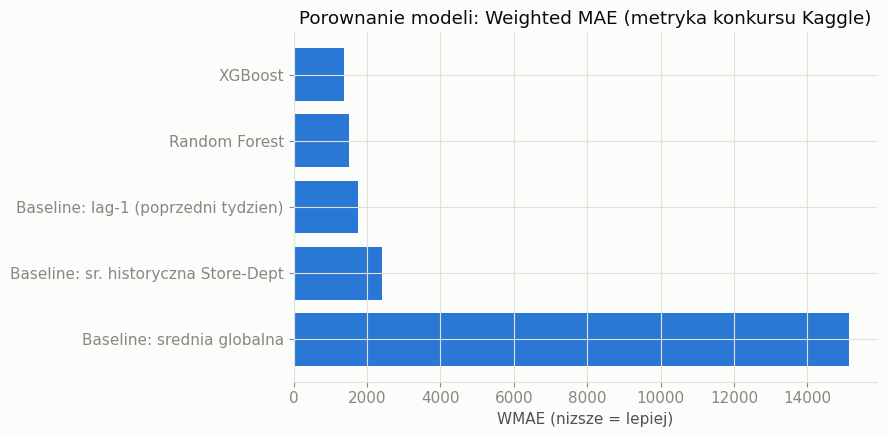

In [23]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(res_df.index[::-1], res_df['WMAE'].values[::-1], color=CAT[0])
ax.set_xlabel('WMAE (nizsze = lepiej)')
ax.set_title('Porownanie modeli: Weighted MAE (metryka konkursu Kaggle)')
plt.tight_layout()
plt.show()

## 10. Ważność cech

Najlepszy model wg WMAE: XGBoost


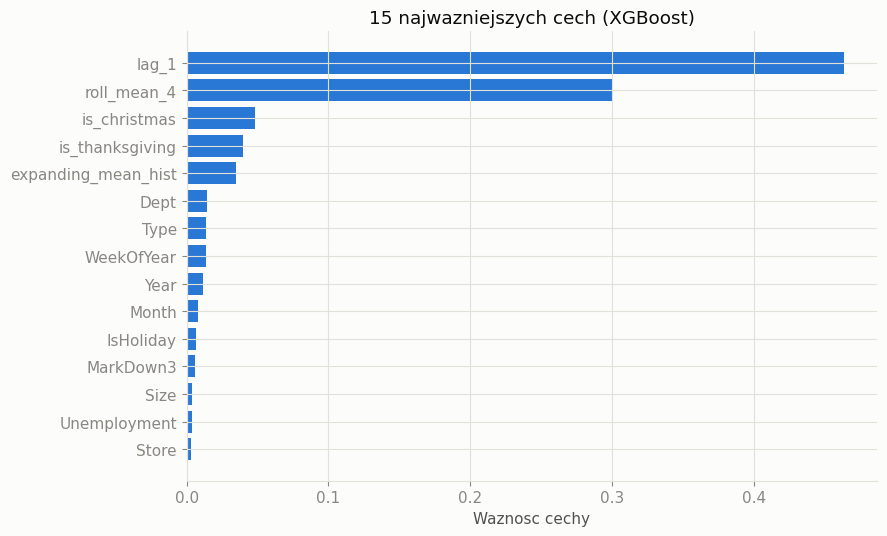

In [24]:
pred_map = {
    'Random Forest': pred_rf,
    'XGBoost': pred_xgb,
    'Baseline: srednia globalna': pred_global_mean,
    'Baseline: sr. historyczna Store-Dept': test['expanding_mean_hist'].values,
    'Baseline: lag-1 (poprzedni tydzien)': test['lag_1'].values,
}

best_model_name = res_df.index[0]
print("Najlepszy model wg WMAE:", best_model_name)

importances = None
if best_model_name == 'XGBoost':
    importances = pd.Series(xgb.feature_importances_, index=feature_cols)
elif best_model_name == 'Random Forest':
    importances = pd.Series(rf.feature_importances_, index=feature_cols)

if importances is not None:
    importances = importances.sort_values(ascending=False).head(15)
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.barh(importances.index[::-1], importances.values[::-1], color=CAT[0])
    ax.set_title(f'15 najwazniejszych cech ({best_model_name})')
    ax.set_xlabel('Waznosc cechy')
    plt.tight_layout()
    plt.show()
else:
    print("Zwyciezyl model bazowy - patrz sekcja wnioskow.")

## 11. Analiza błędów

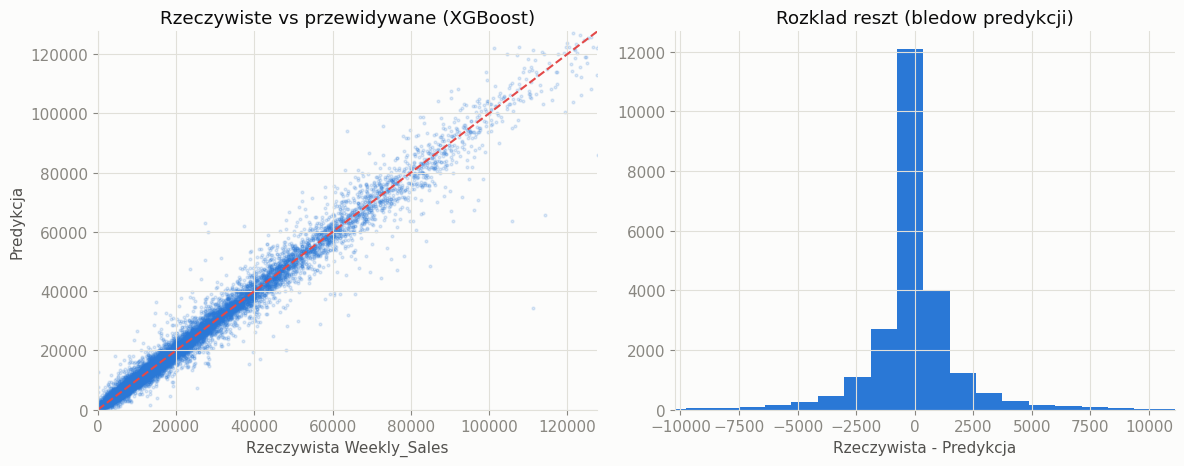

In [25]:
best_pred = np.asarray(pred_map[best_model_name])
residuals = y_test.values - best_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].scatter(y_test.values, best_pred, s=4, alpha=0.15, color=CAT[0])
lims = [0, np.percentile(y_test.values, 99.5)]
axes[0].plot(lims, lims, color=CAT[7], linewidth=1.5, linestyle='--')
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel('Rzeczywista Weekly_Sales'); axes[0].set_ylabel('Predykcja')
axes[0].set_title(f'Rzeczywiste vs przewidywane ({best_model_name})')

axes[1].hist(residuals, bins=100, color=CAT[0])
axes[1].set_xlim(np.percentile(residuals, 0.5), np.percentile(residuals, 99.5))
axes[1].set_title('Rozklad reszt (bledow predykcji)')
axes[1].set_xlabel('Rzeczywista - Predykcja')
plt.tight_layout()
plt.show()

In [26]:
test_copy = test.copy()
test_copy['abs_error'] = np.abs(residuals)

print("Sredni blad bezwzgledny wg IsHoliday:")
print(test_copy.groupby('IsHoliday')['abs_error'].mean())

print("\nSredni blad bezwzgledny wg typu sklepu:")
print(test_copy.groupby('Type')['abs_error'].mean())

print("\nTop 10 dzialow wg sredniego bledu bezwzglednego:")
print(test_copy.groupby('Dept')['abs_error'].mean().sort_values(ascending=False).head(10))

Sredni blad bezwzgledny wg IsHoliday:
IsHoliday
0    1196.660385
1    1614.530572
Name: abs_error, dtype: float64

Sredni blad bezwzgledny wg typu sklepu:
Type
1     610.236499
2    1091.323466
3    1498.848115
Name: abs_error, dtype: float64

Top 10 dzialow wg sredniego bledu bezwzglednego:
Dept
72    5681.969288
38    5157.469995
92    4838.555454
9     3058.730767
95    2814.756186
5     2457.767043
3     2396.436295
23    2324.227802
7     2273.785328
90    1901.180808
Name: abs_error, dtype: float64


## 12. Wnioski i rekomendacje

Zbiór danych po oczyszczeniu i wzbogaceniu o cechy kalendarzowe, promocyjne oraz
historyczne (lag i średnie kroczące liczone wyłącznie na podstawie przeszłości) pozwolił
zbudować model prognozujący `Weekly_Sales` ze znacznie wyższą trafnością niż jakikolwiek
prosty punkt odniesienia. Najsłabszy baseline — średnia globalna sprzedaży — praktycznie
nie wyjaśnia zmienności danych (R² ≈ -0,001, WMAE ≈ 15 140 USD), co pokazuje, jak bardzo
zróżnicowana jest sprzedaż między sklepami i działami. Użycie średniej historycznej dla
danej pary sklep–dział radykalnie poprawia wynik (WMAE ≈ 2 405 USD, R² = 0,961), a
najprostsza prognoza „tyle co w zeszłym tygodniu” (lag-1) jest zaskakująco mocnym
punktem odniesienia (WMAE ≈ 1 743 USD, R² = 0,973) — sprzedaż w tym zbiorze jest silnie
autoskorelowana w czasie.

Oba wytrenowane modele uczenia maszynowego pobiły wszystkie baseline'y. Random Forest
osiągnął WMAE ≈ 1 507 USD i R² = 0,982, natomiast XGBoost okazał się najlepszym modelem
w całym eksperymencie: WMAE ≈ 1 371 USD, MAE ≈ 1 249 USD, RMSE ≈ 2 609 USD, R² = 0,986,
przy czasie trenowania rzędu kilkunastu sekund (znacznie krótszym niż Random Forest).
Zdecydowanie najważniejsze cechy dla modelu to informacje historyczne o sprzedaży —
`lag_1` (sprzedaż z poprzedniego tygodnia) i `roll_mean_4` (średnia z ostatnich 4 tygodni)
razem odpowiadają za większość łącznej ważności cech. Zaraz za nimi plasują się flagi
konkretnych świąt (`is_christmas`, `is_thanksgiving`) oraz `expanding_mean_hist`, a dopiero
dalej: `Dept`, `Type`, `WeekOfYear` i `Year`. `Size` oraz cechy makroekonomiczne (CPI,
bezrobocie, cena paliwa, temperatura) mają w tym modelu znaczenie drugorzędne — potwierdza
to, że najlepszym predyktorem przyszłej sprzedaży danego sklepu i działu jest jego własna
niedawna historia, wzmocniona informacją o zbliżających się największych świętach.

Analiza błędów pokazuje, że model myli się bardziej w tygodniach świątecznych (średni
błąd bezwzględny ≈ 1 615 USD) niż w zwykłych tygodniach (≈ 1 197 USD), co jest zgodne z
intuicją — święta wprowadzają nietypowe, trudniejsze do przewidzenia skoki popytu, a w
zbiorze treningowym jest ich stosunkowo mało. Błąd rośnie też wraz z „rozmiarem” sklepu:
Typ 1 (największe sklepy) ma najniższy średni błąd (≈ 610 USD), a Typ 3 (najmniejsze)
najwyższy (≈ 1 499 USD) — w kategoriach względnych, czyli jako odsetek typowej sprzedaży,
różnica ta jest jednak znacznie mniejsza. Największe błędy bezwzględne koncentrują się w
kilku działach o wysokiej i zmiennej sprzedaży (m.in. Dział 72, 38 i 92), co pokrywa się z
wcześniejszą obserwacją z EDA, że to właśnie te działy generują ekstremalne wartości
sprzedaży w tygodniach świątecznych.

**Rekomendacje.** Do produkcyjnego użycia rekomendowany jest model XGBoost z cechami
historycznymi opartymi na przeszłości — jest najdokładniejszy i najszybszy w trenowaniu.
Warto rozważyć dalsze usprawnienia: dodanie cechy „tydzień do najbliższego święta” zamiast
tylko binarnych flag konkretnych świąt, osobne modele lub wagi dla działów o ekstremalnej
zmienności (72, 38, 92), a także walidację krzyżową typu *rolling origin* (kilka okien
czasowych zamiast jednego podziału na 8 ostatnich tygodni) w celu bardziej wiarygodnej
oceny stabilności modelu w czasie. Dla działów o krótkiej historii (nowo otwarte lub
sezonowe) warto też przetestować model osobny lub cechy oparte na podobnych działach w
innych sklepach, ponieważ brakująca historia dla pierwszej obserwacji (3 331 par
sklep–dział) jest obecnie uzupełniana średnią działu, co jest rozwiązaniem uproszczonym.